# Import Library

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso


In [3]:
df=pd.read_csv("ToyotaCorolla - MLR.xls")
df.head()

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170


In [4]:
df.shape

(1436, 11)

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Price,1436.0,10730.824513,3626.964585,4350.0,8450.0,9900.0,11950.00,32500.0
Age_08_04,1436.0,55.947075,18.599988,1.0,44.0,61.0,70.00,80.0
KM,1436.0,68533.259749,37506.448872,1.0,43000.0,63389.5,87020.75,243000.0
HP,1436.0,101.502089,14.981080,69.0,90.0,110.0,110.00,192.0
Automatic,1436.0,0.055710,0.229441,0.0,0.0,0.0,0.00,1.0
cc,1436.0,1576.855850,424.386770,1300.0,1400.0,1600.0,1600.00,16000.0
Doors,1436.0,4.033426,0.952677,2.0,3.0,4.0,5.00,5.0
Cylinders,1436.0,4.000000,0.000000,4.0,4.0,4.0,4.00,4.0
Gears,1436.0,5.026462,0.188510,3.0,5.0,5.0,5.00,6.0
Weight,1436.0,1072.459610,52.641120,1000.0,1040.0,1070.0,1085.00,1615.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Price      1436 non-null   int64
 1   Age_08_04  1436 non-null   int64
 2   KM         1436 non-null   int64
 3   Fuel_Type  1436 non-null   str  
 4   HP         1436 non-null   int64
 5   Automatic  1436 non-null   int64
 6   cc         1436 non-null   int64
 7   Doors      1436 non-null   int64
 8   Cylinders  1436 non-null   int64
 9   Gears      1436 non-null   int64
 10  Weight     1436 non-null   int64
dtypes: int64(10), str(1)
memory usage: 123.5 KB


# Data Cleaning

In [7]:
df.isnull().sum()

Price        0
Age_08_04    0
KM           0
Fuel_Type    0
HP           0
Automatic    0
cc           0
Doors        0
Cylinders    0
Gears        0
Weight       0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

Price        int64
Age_08_04    int64
KM           int64
Fuel_Type      str
HP           int64
Automatic    int64
cc           int64
Doors        int64
Cylinders    int64
Gears        int64
Weight       int64
dtype: object

## EDA

In [12]:
numeric=df.select_dtypes(include=(np.number))
numeric.head()

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,90,0,2000,3,4,5,1165
1,13750,23,72937,90,0,2000,3,4,5,1165
2,13950,24,41711,90,0,2000,3,4,5,1165
3,14950,26,48000,90,0,2000,3,4,5,1165
4,13750,30,38500,90,0,2000,3,4,5,1170


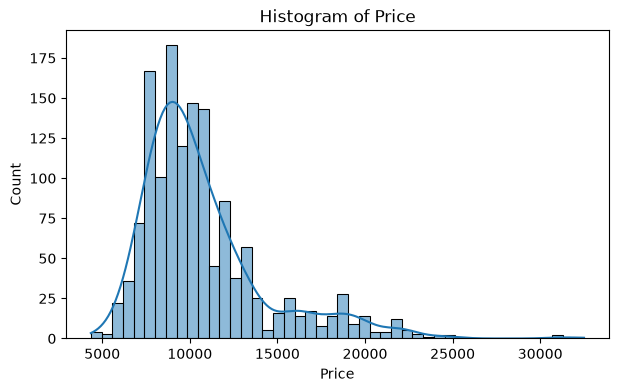

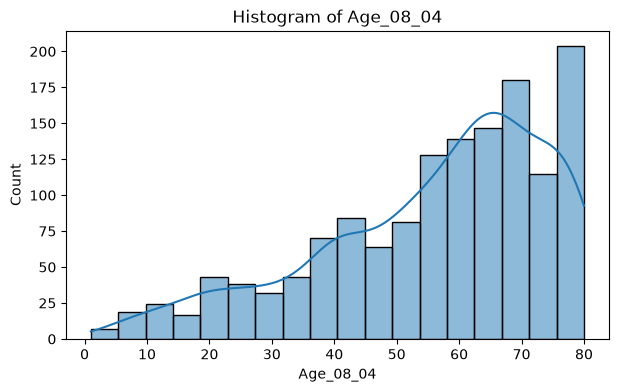

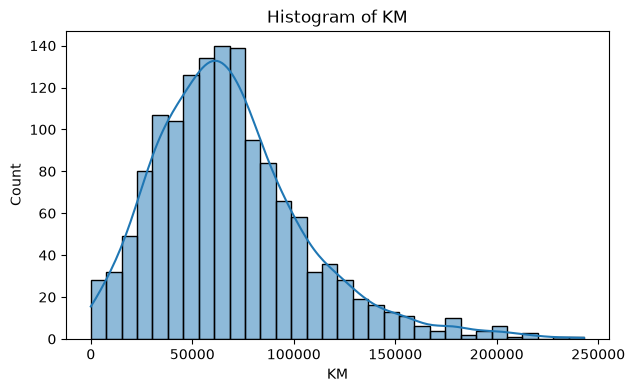

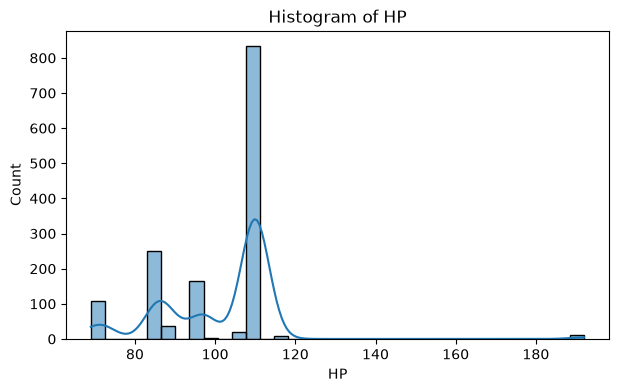

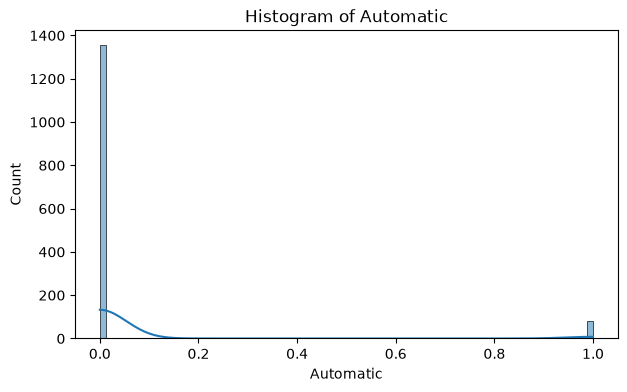

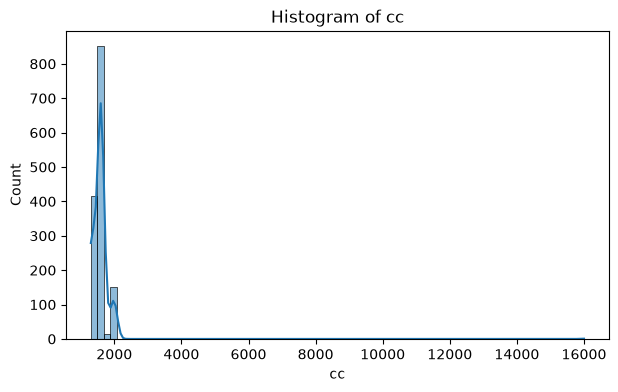

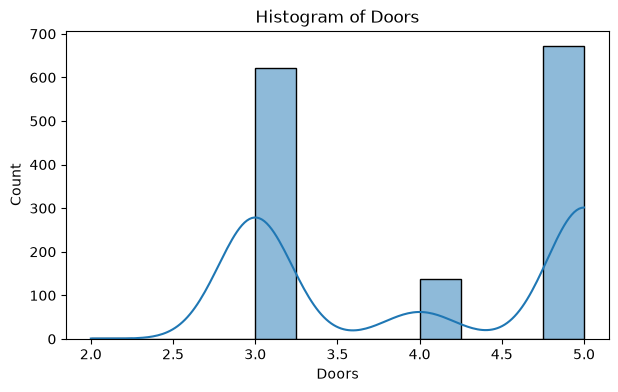

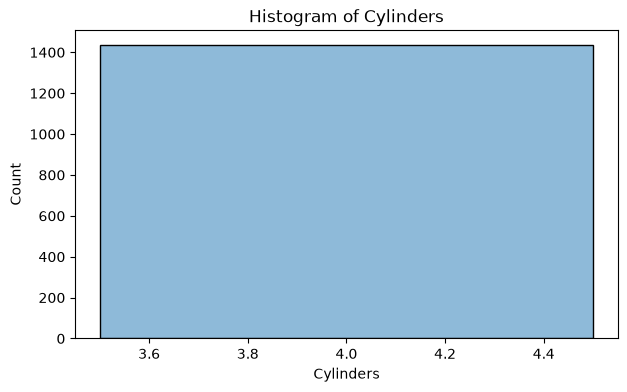

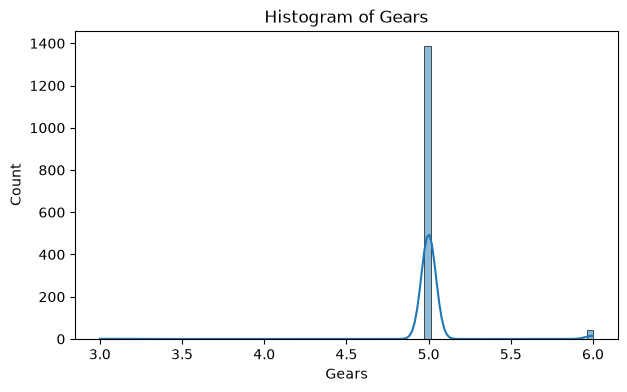

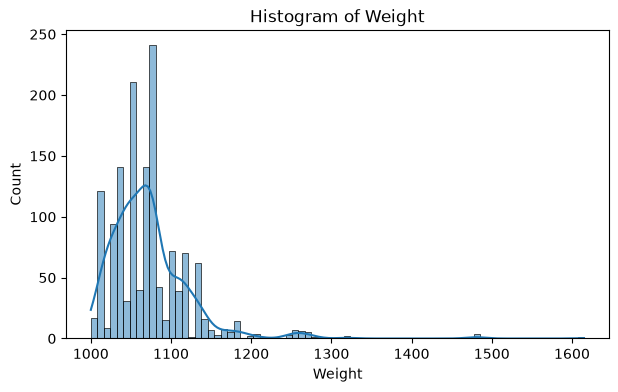

In [14]:
#histogram
for col in numeric:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col],kde=True)
    plt.title(f"Histogram of {col}")
    plt.show()


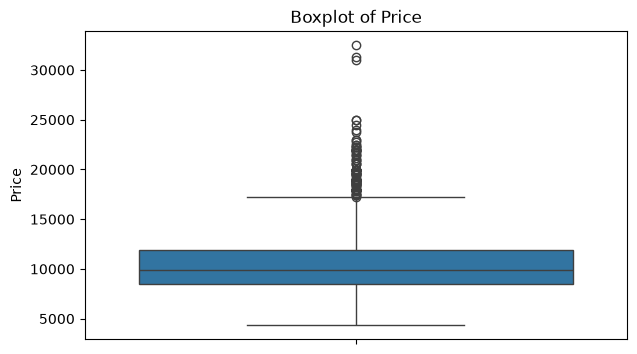

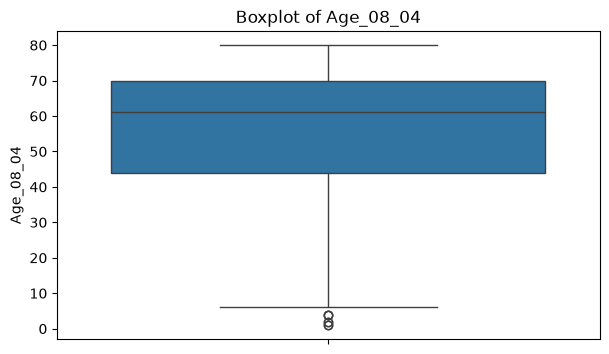

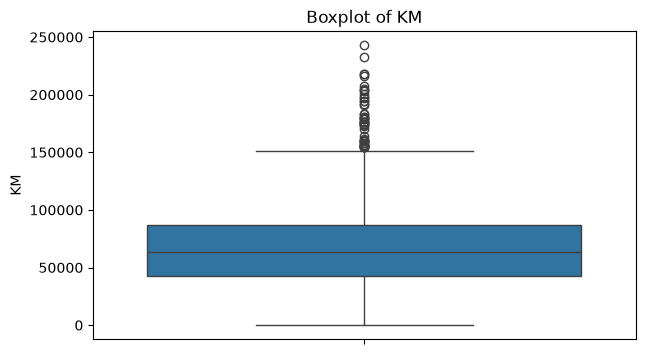

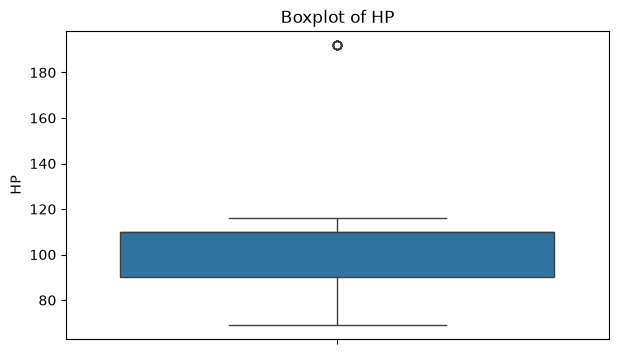

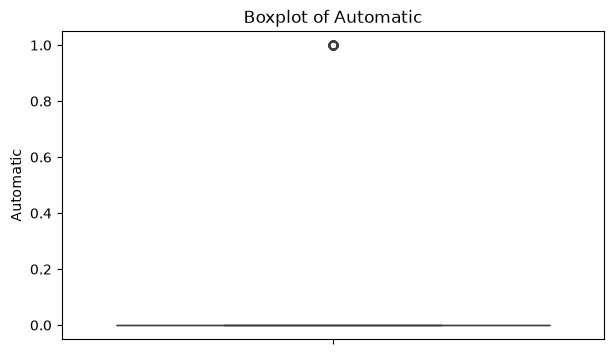

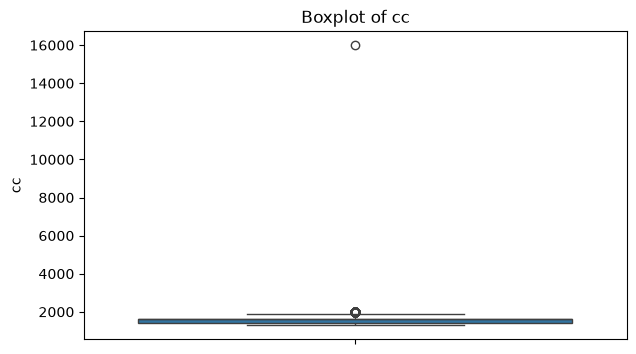

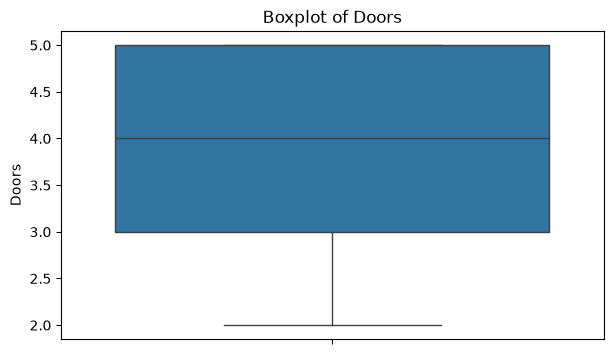

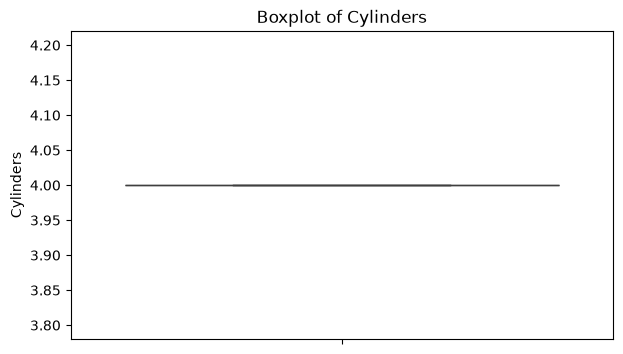

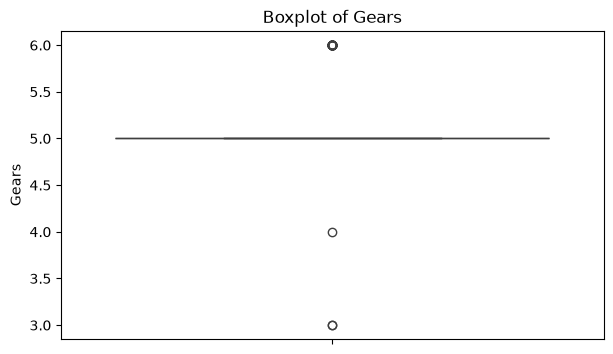

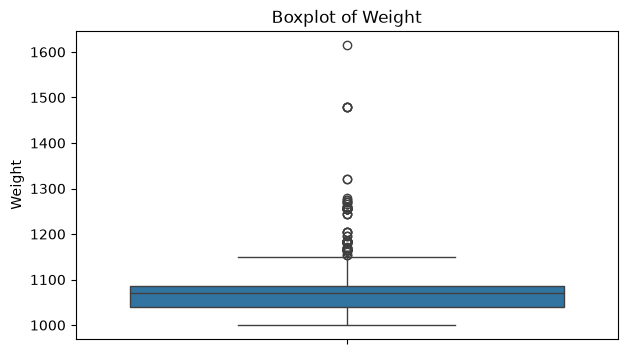

In [17]:
for col in numeric:
    plt.figure(figsize=(7,4))
    sns.boxplot(df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

### Remove Outlayer

In [22]:
for col in numeric:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR = Q3-Q1

    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    df[col]=df[col].clip(lower,upper)

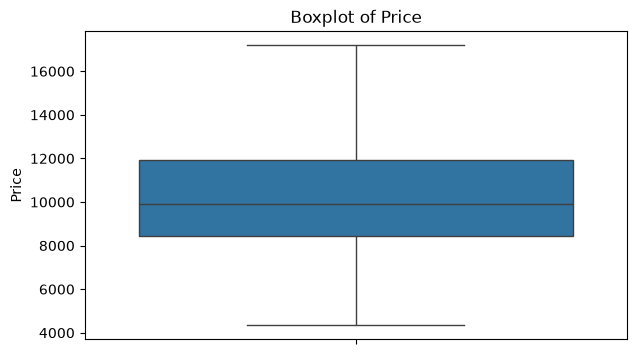

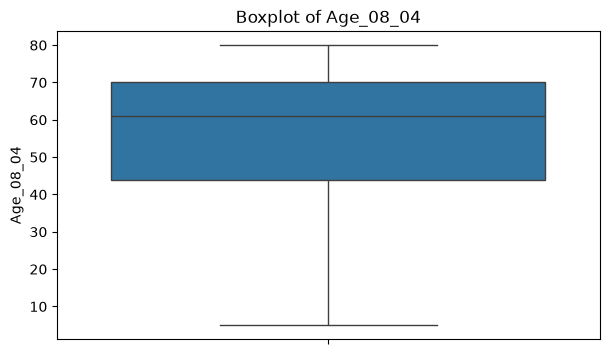

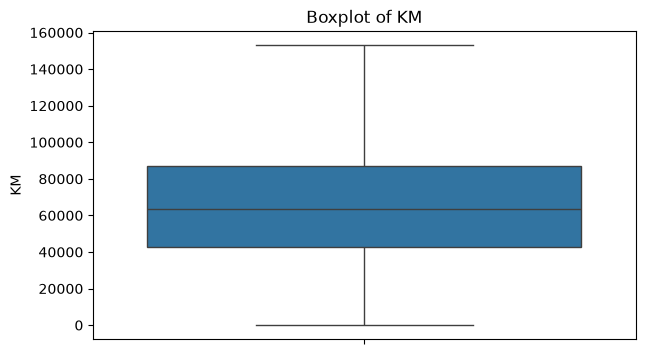

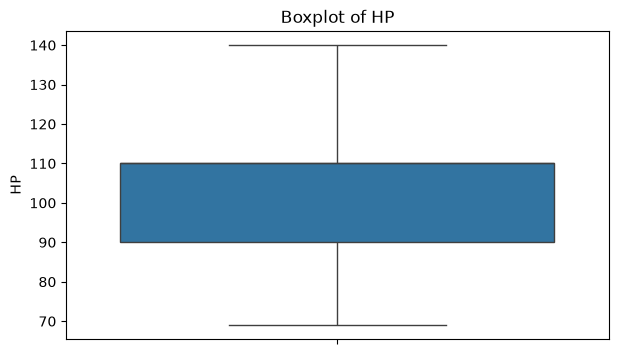

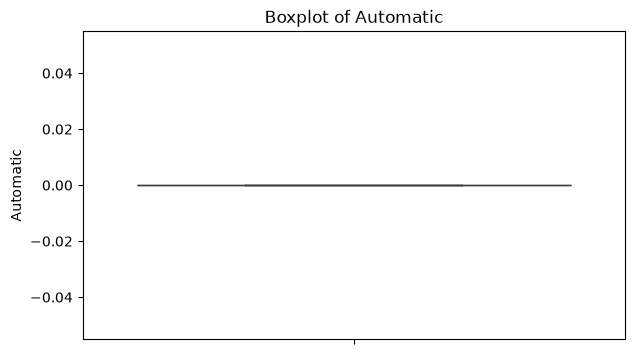

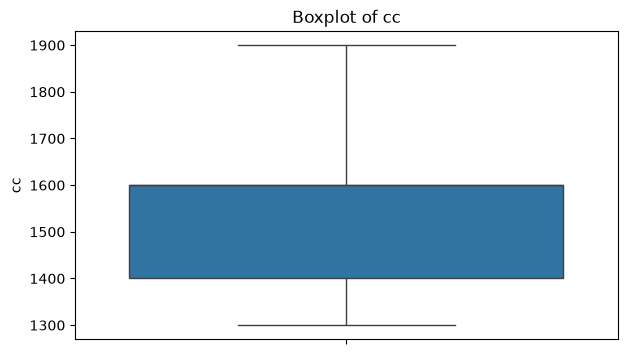

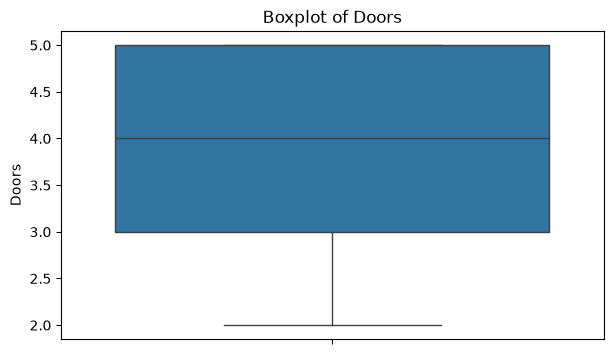

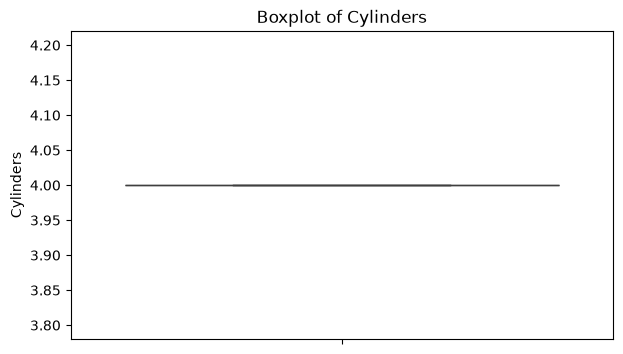

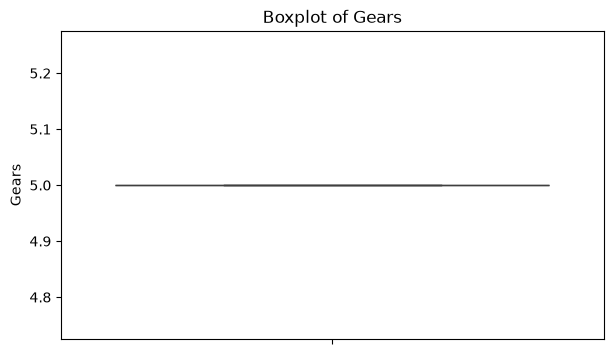

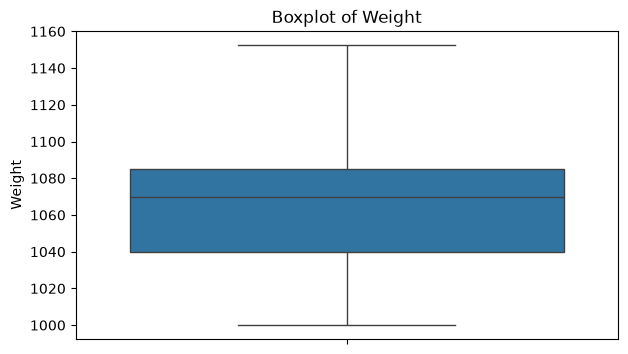

In [23]:
for col in numeric:
    plt.figure(figsize=(7,4))
    sns.boxplot(df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

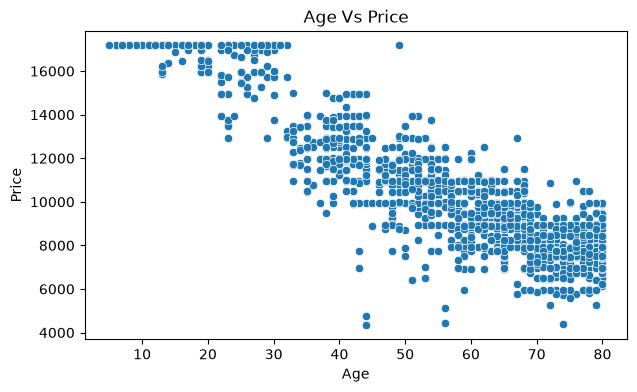

In [26]:
#scatter
plt.figure(figsize=(7,4))
sns.scatterplot(x=df['Age_08_04'],y=df['Price'])
plt.title('Age Vs Price')
plt.xlabel('Age')
plt.ylabel('Price')
plt.show()

In [27]:
#heatmap
corr=numeric.corr()
corr

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
Price,1.000000,-0.876273,-0.569420,0.314134,0.033928,0.124375,0.183604,NaN,0.063831,0.575869
Age_08_04,-0.876273,1.000000,0.504575,-0.155293,0.031354,-0.096549,-0.146929,NaN,-0.005629,-0.466484
KM,-0.569420,0.504575,1.000000,-0.332904,-0.082168,0.103822,-0.035193,NaN,0.014890,-0.023969
HP,0.314134,-0.155293,-0.332904,1.000000,0.013313,0.035207,0.091803,NaN,0.209642,0.087143
Automatic,0.033928,0.031354,-0.082168,0.013313,1.000000,0.066934,-0.027492,NaN,-0.098582,0.058499
cc,0.124375,-0.096549,0.103822,0.035207,0.066934,1.000000,0.079254,NaN,0.014732,0.335077
Doors,0.183604,-0.146929,-0.035193,0.091803,-0.027492,0.079254,1.000000,NaN,-0.160101,0.301734
Cylinders,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gears,0.063831,-0.005629,0.014890,0.209642,-0.098582,0.014732,-0.160101,NaN,1.000000,0.021238
Weight,0.575869,-0.466484,-0.023969,0.087143,0.058499,0.335077,0.301734,NaN,0.021238,1.000000


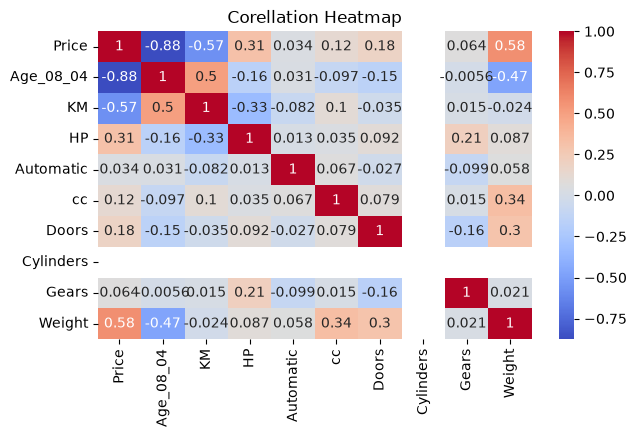

In [29]:
plt.figure(figsize=(7,4))
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.title("Corellation Heatmap")
plt.show()

# Data Processing

In [35]:
!pip install scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
ss_x=ss.fit_transform(numeric)
ss_x=pd.DataFrame(ss_x)
ss_x.columns=list(numeric)
ss_x

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,0.770368,-1.777268,-0.575958,-0.767351,-0.242983,0.998113,-1.084443,0.0,-0.140475,1.774964
1,0.839669,-1.777268,0.116474,-0.767351,-0.242983,0.998113,-1.084443,0.0,-0.140475,1.774964
2,0.895109,-1.723380,-0.716707,-0.767351,-0.242983,0.998113,-1.084443,0.0,-0.140475,1.774964
3,1.172311,-1.615603,-0.548902,-0.767351,-0.242983,0.998113,-1.084443,0.0,-0.140475,1.774964
4,0.839669,-1.400049,-0.802384,-0.767351,-0.242983,0.998113,-1.084443,0.0,-0.140475,1.870688
...,...,...,...,...,...,...,...,...,...,...
1430,-0.892845,0.701602,-1.281492,-1.034441,-0.242983,-0.651898,-1.084443,0.0,-0.140475,-0.905299
1431,0.034396,0.863267,-1.322689,-1.034441,-0.242983,-0.651898,-1.084443,0.0,-0.140475,-1.096747
1432,-0.615643,0.809379,-1.375627,-1.034441,-0.242983,-0.651898,-1.084443,0.0,-0.140475,-1.096747
1433,-0.962145,0.755490,-1.378295,-1.034441,-0.242983,-0.651898,-1.084443,0.0,-0.140475,-1.096747


In [37]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df["Fuel_Type"]=le.fit_transform(df["Fuel_Type"])
cat=df[df.columns[[0]]]
df.head()

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986.0,1,90,0,1900,3,4,5,1152.5
1,13750,23,72937.0,1,90,0,1900,3,4,5,1152.5
2,13950,24,41711.0,1,90,0,1900,3,4,5,1152.5
3,14950,26,48000.0,1,90,0,1900,3,4,5,1152.5
4,13750,30,38500.0,1,90,0,1900,3,4,5,1152.5


# variable Selection

In [41]:
x=df.drop('Price',axis=1)
y=df['Price']

# 

# Data Partition

In [49]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=55)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1148, 10)
X_test: (287, 10)
y_train: (1148,)
y_test: (287,)


# model Training

In [50]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)
y_pred_train=model.predict(X_train)
y_pred_test=model.predict(X_test)

# model Evaluation

In [52]:
#root_mean_squared_error
from sklearn.metrics import root_mean_squared_error
rmse_train = root_mean_squared_error(y_train, y_pred_train)
rmse_test = root_mean_squared_error(y_test, y_pred_test)

print("Train RMSE:", np.round(rmse_train, 2))
print("Test RMSE:", np.round(rmse_test, 2))


Train RMSE: 1103.43
Test RMSE: 1050.34


In [53]:
from sklearn.metrics import mean_squared_error
mse_train = mean_squared_error(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)

print("Train MSE:", np.round(mse_train, 2))
print("Test MSE:", np.round(mse_test, 2))

Train MSE: 1217558.46
Test MSE: 1103209.51


In [56]:
from sklearn.metrics import r2_score
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

print("Train R2:", np.round(r2_train, 2))
print("Test R2:", np.round(r2_test, 2))

Train R2: 0.86
Test R2: 0.87


In [58]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(
    model, x, y,
    cv=5,
    scoring='r2'
)

print("CV Scores:", scores)
print("Average R2:", np.mean(scores))

CV Scores: [ 0.53619888  0.44089682  0.30953392  0.55763988 -0.23438648]
Average R2: 0.32197660342284085


In [59]:
from sklearn.neighbors import KNeighborsRegressor
model = KNeighborsRegressor(n_neighbors=5)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.37216362549366144
